In [2]:
import numpy as np

import matplotlib.pyplot as plt

studentId = "R00277227"

a = 7
b = 2
seed = 100 + 10 * a + b
np.random.seed(seed)

print("Seed used:", seed)

Seed used: 172


## Dataset A

In [3]:
# Means
mean1 = [-4 - 0.1 * a, 4 + 0.1 * b]
mean2 = [0, -4 - 0.1 * a]
mean3 = [4 + 0.1 * b, 4]

cov = np.eye(2)

#40 points per cluster
cluster1 = np.random.multivariate_normal(mean1, cov, 40)
cluster2 = np.random.multivariate_normal(mean2, cov, 40)
cluster3 = np.random.multivariate_normal(mean3, cov, 40)

# Combine
data_A = np.vstack((cluster1, cluster2, cluster3))

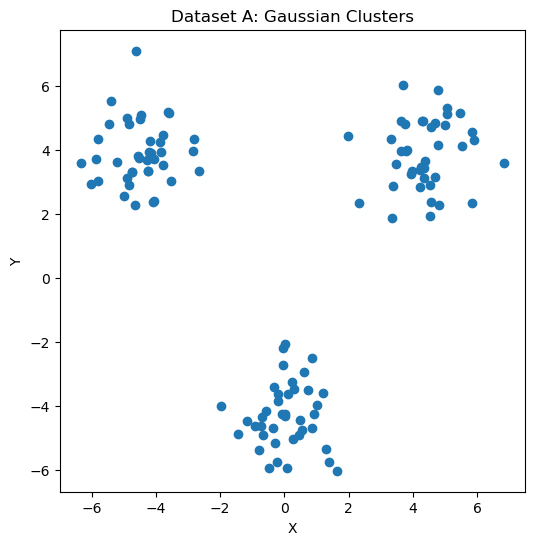

In [4]:
plt.figure(figsize=(6,6))
plt.scatter(data_A[:,0], data_A[:,1])
plt.title("Dataset A: Gaussian Clusters")
plt.xlabel("X")
plt.ylabel("Y")
plt.show()

In [5]:
mean_x_A = np.mean(data_A[:,0])
mean_y_A = np.mean(data_A[:,1])

std_x_A = np.std(data_A[:,0])
std_y_A = np.std(data_A[:,1])

print("Dataset A Statistics:")
print("Mean (X, Y):", mean_x_A, mean_y_A)
print("Std Dev (X, Y):", std_x_A, std_y_A)

Dataset A Statistics:
Mean (X, Y): -0.020435092792113953 1.1555824895377806
Std Dev (X, Y): 3.711871864961598 3.976466659778563


## Dataset B

In [6]:
theta = np.random.uniform(0, 2*np.pi, 70)
epsilon = np.random.normal(0, 0.25, 70)
r = 4.5 + epsilon

x_ring = r * np.cos(theta)
y_ring = r * np.sin(theta)

ring = np.column_stack((x_ring, y_ring))

In [7]:
mean_blob = [5 + 0.1 * a, 0]
cov_blob = 0.5 * np.eye(2)

blob = np.random.multivariate_normal(mean_blob, cov_blob, 30)

In [8]:
noise = np.random.uniform(-7, 7, (20, 2))

In [9]:
data_B = np.vstack((ring, blob, noise))

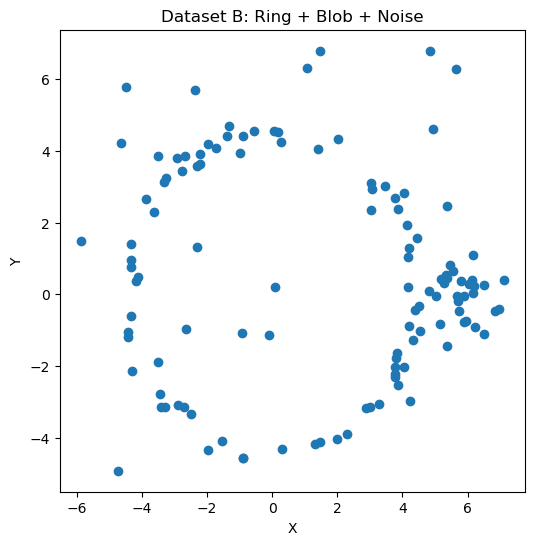

In [10]:
plt.figure(figsize=(6,6))
plt.scatter(data_B[:,0], data_B[:,1])
plt.title("Dataset B: Ring + Blob + Noise")
plt.xlabel("X")
plt.ylabel("Y")
plt.show()

In [11]:
mean_x_B = np.mean(data_B[:,0])
mean_y_B = np.mean(data_B[:,1])

std_x_B = np.std(data_B[:,0])
std_y_B = np.std(data_B[:,1])

print("\nDataset B Statistics:")
print("Mean (X, Y):", mean_x_B, mean_y_B)
print("Std Dev (X, Y):", std_x_B, std_y_B)


Dataset B Statistics:
Mean (X, Y): 1.4257629604251596 0.5597705964919366
Std Dev (X, Y): 3.820895176728409 2.907670475451719


## Task 2

In [12]:
def euclidean_distance(p, c):
    return np.sqrt((p[0] - c[0])**2 + (p[1] - c[1])**2)

In [13]:
def compute_sse(X, centroids, labels):
    sse = 0
    for i in range(len(X)):
        c = centroids[labels[i]]
        sse += (X[i,0] - c[0])**2 + (X[i,1] - c[1])**2
    return sse

In [14]:
def initialize_centroids(X, K):
    centroids = []

    # 1st centroid
    idx = np.argmin(X[:,0] + X[:,1])
    centroids.append(X[idx].astype(float))

    # remaining centroids
    while len(centroids) < K:
        best_point = None
        best_dist = -1

        for x in X:
            dist = min([euclidean_distance(x, c) for c in centroids])
            if dist > best_dist:
                best_dist = dist
                best_point = x

        centroids.append(best_point.astype(float))

    return np.array(centroids)

In [15]:
def prototype_clustering(X, K, alpha=0.05, epochs=200):

    centroids = initialize_centroids(X, K)

    sse_history = []
    centroid_history = []

    for epoch in range(epochs):

        labels = np.zeros(len(X), dtype=int)
        assignments = [[] for _ in range(K)]

        #ONLINE PROCESSING
        for i in range(len(X)):
            x = X[i]

            distances = [euclidean_distance(x, c) for c in centroids]
            k = np.argmin(distances)

            labels[i] = k
            assignments[k].append(x)

            # UPDATE RULE
            if x[0] > centroids[k][0]:
                centroids[k][0] += alpha
            elif x[0] < centroids[k][0]:
                centroids[k][0] -= alpha

            if x[1] > centroids[k][1]:
                centroids[k][1] += alpha
            elif x[1] < centroids[k][1]:
                centroids[k][1] -= alpha


        for k in range(K):
            if len(assignments[k]) == 0:
                dx = np.random.uniform(-0.5, 0.5)
                dy = np.random.uniform(-0.5, 0.5)
                centroids[k][0] += dx
                centroids[k][1] += dy

        # -------- SSE --------
        sse = compute_sse(X, centroids, labels)
        sse_history.append(sse)

        centroid_history.append(centroids.copy())

    return centroids, sse_history, centroid_history

In [16]:
def plot_clusters(X, centroids, title):
    plt.figure(figsize=(6,6))

    labels = np.zeros(len(X), dtype=int)
    for i in range(len(X)):
        dists = [euclidean_distance(X[i], c) for c in centroids]
        labels[i] = np.argmin(dists)

    colors = ['blue', 'green', 'orange']
    for k in range(len(centroids)):
        pts = X[labels == k]
        plt.scatter(pts[:,0], pts[:,1], s=15, color=colors[k], label=f'Cluster {k+1}')

    plt.scatter(centroids[:,0], centroids[:,1],
                c='red', s=200, marker='X', label='Centroids')

    plt.title(title)
    plt.legend()
    plt.show()

In [17]:
def plot_centroid_paths(history, title):
    plt.figure(figsize=(6,6))

    K = len(history[0])
    colors = ['blue', 'green', 'orange']
    snapshot_epochs = [49, 99, 149, 199]  # every 50 epochs

    for k in range(K):
        for ep in snapshot_epochs:
            cx = history[ep][k][0]
            cy = history[ep][k][1]
            plt.scatter(cx, cy, color=colors[k], s=80,
                        label=f'Centroid {k+1} ep={ep+1}' if k == 0 else "")
            plt.annotate(f'ep{ep+1}', (cx, cy), fontsize=7, ha='right')

    plt.title(title + " - Centroid Positions Every 50 Epochs")
    plt.show()

In [18]:
def plot_sse_curves(sse_list, label):
    plt.plot(sse_list, label=label)

Final Centroids A:
 [[-0.07632561 -4.41690798]
 [-4.50753894  3.68515655]
 [ 4.5242403   3.96983369]]


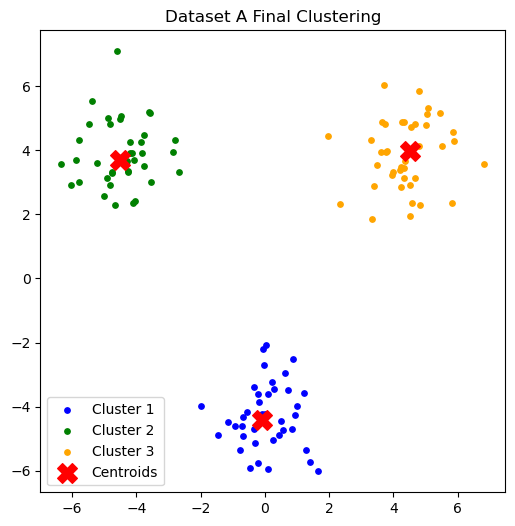

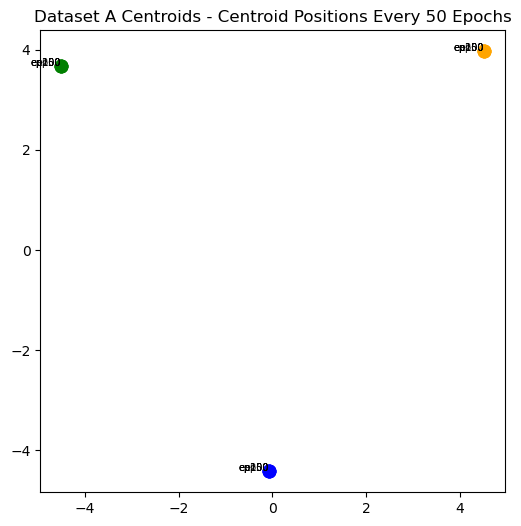

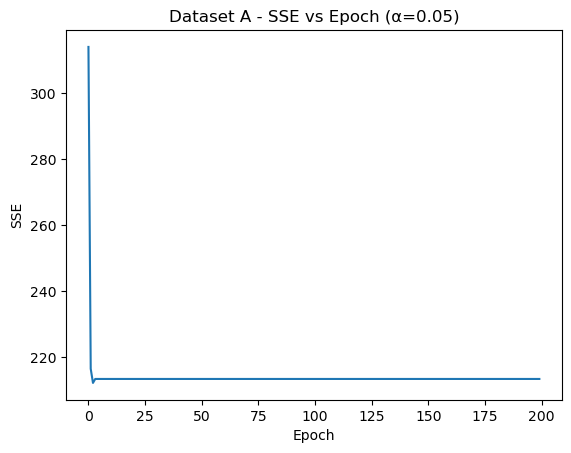

In [19]:
K = 3
alpha = 0.05

centroids_A, sse_A, hist_A = prototype_clustering(data_A, K, alpha)

print("Final Centroids A:\n", centroids_A)

plot_clusters(data_A, centroids_A, "Dataset A Final Clustering")
plot_centroid_paths(hist_A, "Dataset A Centroids")

# SSE vs Epoch - Dataset A
plt.figure()
plt.plot(sse_A)
plt.title("Dataset A - SSE vs Epoch (α=0.05)")
plt.xlabel("Epoch")
plt.ylabel("SSE")
plt.show()

Final Centroids B:
 [[-2.51713824  1.4783033 ]
 [ 5.25769656  0.18060121]]


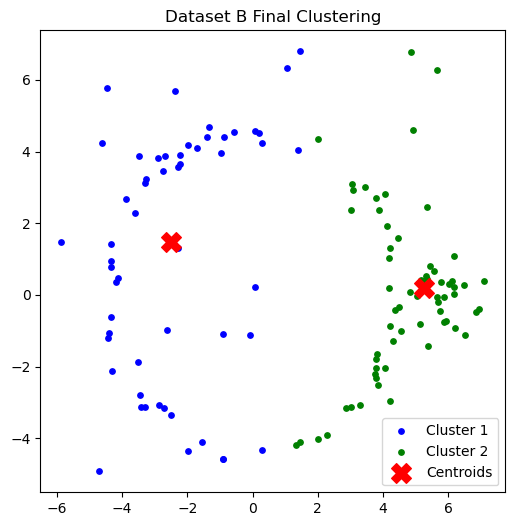

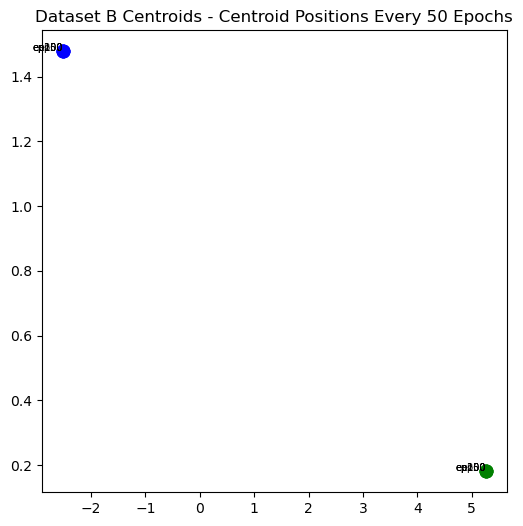

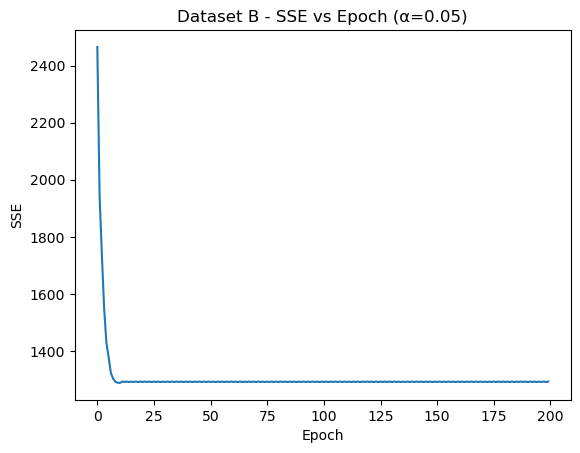

In [20]:
K = 2

centroids_B, sse_B, hist_B = prototype_clustering(data_B, K, alpha)

print("Final Centroids B:\n", centroids_B)

plot_clusters(data_B, centroids_B, "Dataset B Final Clustering")
plot_centroid_paths(hist_B, "Dataset B Centroids")

# SSE vs Epoch - Dataset B
plt.figure()
plt.plot(sse_B)
plt.title("Dataset B - SSE vs Epoch (α=0.05)")
plt.xlabel("Epoch")
plt.ylabel("SSE")
plt.show()

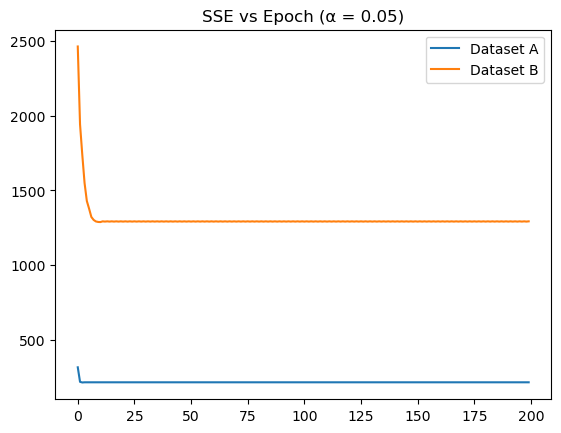

In [21]:
plt.figure()

plt.plot(sse_A, label="Dataset A")
plt.plot(sse_B, label="Dataset B")

plt.title("SSE vs Epoch (α = 0.05)")
plt.legend()
plt.show()

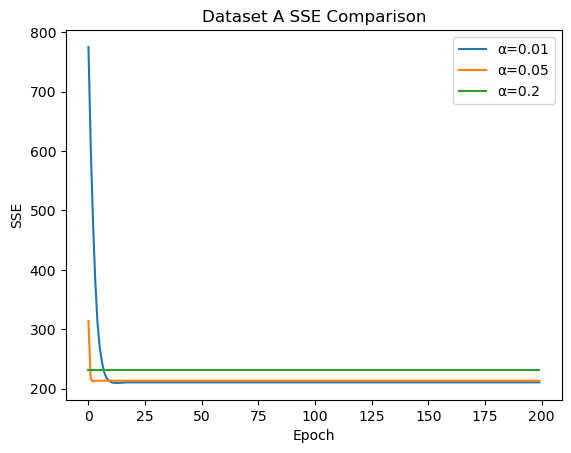

In [22]:
# Dataset A learning rate comparison
alphas = [0.01, 0.05, 0.2]
plt.figure()

for i in alphas:
    np.random.seed(172)  
    _, sse, _ = prototype_clustering(data_A, 3, i)
    plt.plot(sse, label=f"α={i}")

plt.title("Dataset A SSE Comparison")
plt.xlabel("Epoch")
plt.ylabel("SSE")
plt.legend()
plt.show()

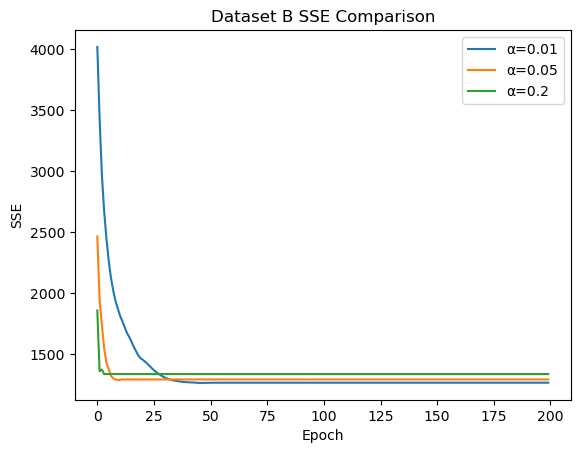

In [23]:
# Dataset B learning rate comparison
plt.figure()

for j in alphas:
    np.random.seed(172)  
    _, sse, _ = prototype_clustering(data_B, 2, j)
    plt.plot(sse, label=f"α={j}")

plt.title("Dataset B SSE Comparison")
plt.xlabel("Epoch")
plt.ylabel("SSE")
plt.legend()
plt.show()

## Task 3

In [24]:
def knn4_distances(X):
    n = len(X)
    dists = []

    for i in range(n):
        dist_list = []

        for j in range(n):
            if i != j:
                dist = np.sqrt((X[i,0] - X[j,0])**2 + (X[i,1] - X[j,1])**2)
                dist_list.append(dist)

        dist_list.sort()
        dists.append(dist_list[3])  

    return np.sort(np.array(dists))

In [25]:
def plot_knn_curve(distances, title, eps=None):
    plt.figure(figsize=(6,4))
    plt.plot(distances)

    if eps is not None:
        plt.axhline(y=eps, color='red', linestyle='--', linewidth=2,
                    label=f"Chosen ε = {eps}")
        plt.legend()

    plt.title(title)
    plt.xlabel("Points sorted")
    plt.ylabel("4-NN distance")
    plt.show()

In [26]:
def region_query(X, point_idx, eps):
    neighbors = []

    for i in range(len(X)):
        dist = np.sqrt((X[point_idx,0] - X[i,0])**2 +
                       (X[point_idx,1] - X[i,1])**2)
        if dist <= eps:
            neighbors.append(i)

    return neighbors

In [27]:
def expand_cluster(X, labels, point_idx, neighbors, cluster_id, eps, minPts):

    labels[point_idx] = cluster_id
    i = 0

    while i < len(neighbors):
        n_idx = neighbors[i]

        if labels[n_idx] == -1:
            labels[n_idx] = cluster_id

        elif labels[n_idx] == 0:
            labels[n_idx] = cluster_id
            new_neighbors = region_query(X, n_idx, eps)

            if len(new_neighbors) >= minPts:
                neighbors += new_neighbors

        i += 1

In [28]:
def dbscan(X, eps, minPts=4):

    labels = np.zeros(len(X))  
    cluster_id = 0

    for i in range(len(X)):

        if labels[i] != 0:
            continue

        neighbors = region_query(X, i, eps)

        if len(neighbors) < minPts:
            labels[i] = -1  # noise
        else:
            cluster_id += 1
            expand_cluster(X, labels, i, neighbors, cluster_id, eps, minPts)

    return labels

In [29]:
def plot_dbscan(X, labels, title):

    plt.figure(figsize=(6,6))

    unique_labels = set(labels)

    for l in unique_labels:
        if l == -1:
            color = "black"
            label_name = "Noise"
        else:
            color = None
            label_name = f"Cluster {int(l)}"

        pts = X[labels == l]
        plt.scatter(pts[:,0], pts[:,1], label=label_name)

    plt.title(title)
    plt.legend()
    plt.show()

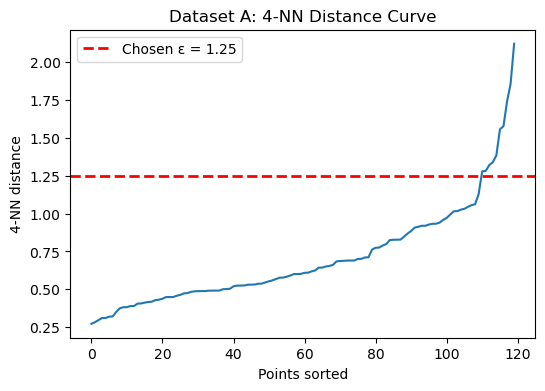

Chosen eps for Dataset A: 1.25


In [30]:
knn_A = knn4_distances(data_A)

eps_A = 1.25

plot_knn_curve(knn_A, "Dataset A: 4-NN Distance Curve", eps=eps_A)

print("Chosen eps for Dataset A:", eps_A)

labels_A = dbscan(data_A, eps_A, minPts=4)

Dataset A
Clusters found: 3
Noise points: 2


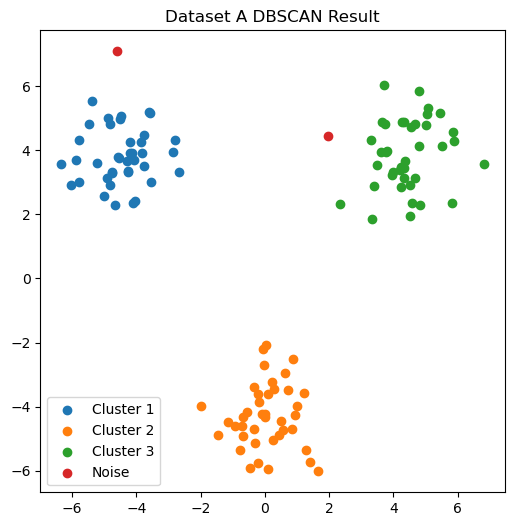

In [31]:
clusters_A = len(set(labels_A)) - (1 if -1 in labels_A else 0)
noise_A = list(labels_A).count(-1)

print("Dataset A")
print("Clusters found:", clusters_A)
print("Noise points:", noise_A)
plot_dbscan(data_A, labels_A, "Dataset A DBSCAN Result")

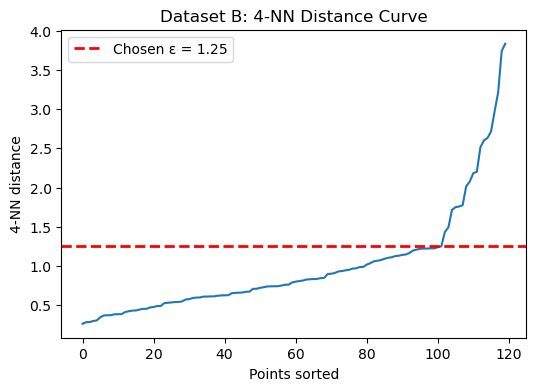

Chosen eps for Dataset B: 1.25


In [32]:
knn_B = knn4_distances(data_B)

eps_B = 1.25

plot_knn_curve(knn_B, "Dataset B: 4-NN Distance Curve", eps=eps_B)

print("Chosen eps for Dataset B:", eps_B)

labels_B = dbscan(data_B, eps_B, minPts=4)

Dataset B
Clusters found: 1
Noise points: 15


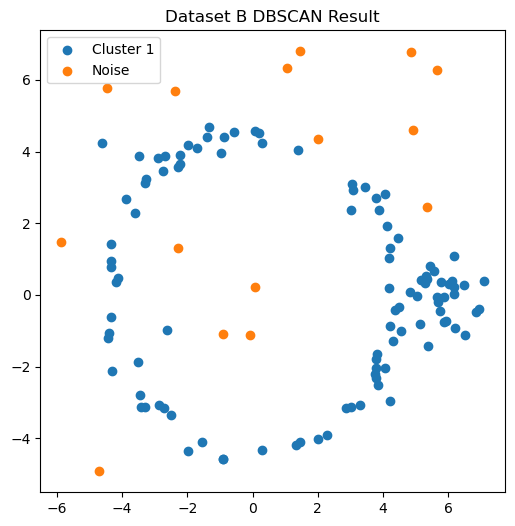

In [33]:
clusters_B = len(set(labels_B)) - (1 if -1 in labels_B else 0)
noise_B = list(labels_B).count(-1)

print("Dataset B")
print("Clusters found:", clusters_B)
print("Noise points:", noise_B)
plot_dbscan(data_B, labels_B, "Dataset B DBSCAN Result")

## Task 4

In [34]:
def dist(a, b):
    return np.sqrt((a[0]-b[0])**2 + (a[1]-b[1])**2)

In [35]:
def silhouette_score_manual(X, labels):

    labels = np.array(labels)
    unique_labels = set(labels)

    # exclude DBSCAN noise
    valid_labels = [l for l in unique_labels if l != -1]

    scores = []

    for i in range(len(X)):

        # skip noise points
        if labels[i] == -1:
            continue

        same_mask = labels == labels[i]
        intra_points = X[same_mask]

        # ---------------- a(i)
        if len(intra_points) <= 1:
            a_i = 0
        else:
            a_i = np.mean([
                np.linalg.norm(X[i] - p)
                for p in intra_points if not np.array_equal(p, X[i])
            ])

        # ---------------- b(i)
        b_i = None

        for l in valid_labels:
            if l == labels[i]:
                continue

            cluster_points = X[labels == l]

            if len(cluster_points) == 0:
                continue

            avg_dist = np.mean([
                np.linalg.norm(X[i] - p)
                for p in cluster_points
            ])

            if b_i is None:
                b_i = avg_dist
            else:
                b_i = min(b_i, avg_dist)

        # ---------------- SAFETY FIX (IMPORTANT)
        if b_i is None:
            s_i = 0

        else:
            denom = max(a_i, b_i)

            if denom <= 1e-12:
                s_i = 0
            else:
                s_i = (b_i - a_i) / denom

        scores.append(s_i)

    return np.mean(scores) if len(scores) > 0 else 0

In [36]:
# from Task 2
# data_A, data_B
# labels from prototype method must be reconstructed

In [37]:
def get_labels(X, centroids):

    labels = np.zeros(len(X), dtype=int)

    for i in range(len(X)):
        dists = [dist(X[i], c) for c in centroids]
        labels[i] = np.argmin(dists)

    return labels

In [38]:
labels_A_proto = get_labels(data_A, centroids_A)
labels_B_proto = get_labels(data_B, centroids_B)

sil_A_proto = silhouette_score_manual(data_A, labels_A_proto)
sil_B_proto = silhouette_score_manual(data_B, labels_B_proto)

print("Prototype Silhouette A:", sil_A_proto)
print("Prototype Silhouette B:", sil_B_proto)

Prototype Silhouette A: 0.8077047046826159
Prototype Silhouette B: 0.5141879437751258


In [39]:
sil_A_db = silhouette_score_manual(data_A, labels_A)
sil_B_db = silhouette_score_manual(data_B, labels_B)

print("DBSCAN Silhouette A:", sil_A_db)
print("DBSCAN Silhouette B:", sil_B_db)

DBSCAN Silhouette A: 0.8138299247594066
DBSCAN Silhouette B: 0.0


In [40]:
final_sse_A = sse_A[-1]
final_sse_B = sse_B[-1]

In [41]:
clusters_A_db = len(set(labels_A)) - (1 if -1 in labels_A else 0)
noise_A_db = list(labels_A).count(-1)

clusters_B_db = len(set(labels_B)) - (1 if -1 in labels_B else 0)
noise_B_db = list(labels_B).count(-1)

In [42]:
print("\nFINAL COMPARISON TABLE\n")

print("{:<10} {:<12} {:<10} {:<12} {:<15} {:<15}".format(
    "Dataset", "Algorithm", "Clusters", "Noise", "Final SSE", "Silhouette"
))

print("-"*80)

print("{:<10} {:<12} {:<10} {:<12} {:<15} {:<15}".format(
    "A", "Prototype", 3, 0, round(final_sse_A,2), round(sil_A_proto,3)
))

print("{:<10} {:<12} {:<10} {:<12} {:<15} {:<15}".format(
    "A", "DBSCAN", clusters_A_db, noise_A_db, "-", round(sil_A_db,3)
))

print("{:<10} {:<12} {:<10} {:<12} {:<15} {:<15}".format(
    "B", "Prototype", 2, 0, round(final_sse_B,2), round(sil_B_proto,3)
))

print("{:<10} {:<12} {:<10} {:<12} {:<15} {:<15}".format(
    "B", "DBSCAN", clusters_B_db, noise_B_db, "-", round(sil_B_db,3)
))


FINAL COMPARISON TABLE

Dataset    Algorithm    Clusters   Noise        Final SSE       Silhouette     
--------------------------------------------------------------------------------
A          Prototype    3          0            213.35          0.808          
A          DBSCAN       3          2            -               0.814          
B          Prototype    2          0            1292.76         0.514          
B          DBSCAN       1          15           -               0.0            
